# Statistical Arbitrage in Cryptocurrencies — Binance global, 30-coin universe

**Goal (from the project brief):** research profitable momentum and/or reversal strategies in crypto, net of realistic execution costs, combine them, and evaluate the result.

This version follows the instructor's feedback on `project_final_v2.ipynb` (13 Binance.US coins): Sharpe ratios on **daily** returns annualized with **√252**; a **point-in-time universe** of the 30 most liquid Binance global coins each month (no full-sample selection, delisted coins included, stablecoins excluded); a **train / test split** (80 / 20) with every choice made on the training period; 2025 and 2026 reported separately.

**Summary of findings** (final strategy: XS momentum + TS momentum + fire sale + betting against beta, risk parity; net of 20 bps)

| | net Sharpe | beta to BTC | alpha vs BTC (t-stat) |
|---|---|---|---|
| Training, Apr-2021 → Aug-2025 | **1.15** (max drawdown −15%) | 0.05 | 12.9% / yr (2.7) |
| **Test, Sep-2025 → Oct-2026** | **0.32** | 0.04 | 3.0% / yr (0.5) |
| &nbsp;&nbsp;Sep–Dec 2025 | 2.58 | −0.08 | 18.8% / yr (1.6) |
| &nbsp;&nbsp;2026 Jan–Oct | −0.72 | 0.07 | −5.0% / yr (−0.8) |

- **Momentum did not fail in 2026 with 30 coins** (XS: 1.09 in 2026, vs −0.87 with 13 coins).
- **Betting against beta broke down in 2026** (−2.8): the low-beta premium reversed, and risk parity had given BAB ~41% of the capital.
- **Handling the failure (post-hoc, Section 12):** a 30% cap per strategy (no cost in training) → test 0.62; rolling max-Sharpe weights → test 0.90.

**Contents**
0. Setup and helper functions
1. Data and universe
2. Momentum: time horizon
3. Transaction costs and execution
4. A better cross-sectional momentum signal
5. Momentum and activity (volume)
6. Time-series momentum
7. Reversal (7.1 short-term reversal, 7.2 pairs trading, 7.3 fire sale)
8. Betting against beta
9. Combining the strategies
10. Performance evaluation (training period)
11. Test period
12. Handling the failure of BAB: rolling max-Sharpe weights and a 30% cap
13. Conclusions and limitations


## 0. Setup and helper functions

*All functions and constants are in `statarb.py`, shared with the other universe's notebook; each function receives the universe (`univ`), the market (`mkt`) and the equal-weight weights (`ew`) as arguments.*

Same conventions as `project_final_v2.ipynb`:
- 4-hour bars; `held = w.shift(lag)` is the position during each bar (no look-ahead).
- Costs: 20 bps per unit traded (market orders), 7 bps (limit orders).
- Sharpe on **daily-aggregated** returns, annualized with **√252**.

New: **every portfolio only holds coins that are in the universe at that time.** Signals are computed on all coins (a coin entering the universe already has ≥ 60 days of history), then coins outside the universe get weight 0 and the weights are demeaned and scaled among the coins in the universe only. Leaving the universe = weight set to 0, so the cost of replacing coins is included in turnover.

**Coins that stop trading** (delisting, ticker change, collapse: LUNA in May-2022, RNDR, FTM) are handled the same way in every strategy, inside `backtest()`: the coin is closed at its last price, and from the next bar its weight is 0 and the remaining weights are rescaled (long and short legs separately, so each keeps its size; no other coin is added). In the training data every gap in a selected coin's prices is such a stop (no short or exchange-wide gaps), so the rule never triggers by accident.

In [1]:
import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

from statarb import *          # all functions, and COST, COST_LIMIT, DAYS_PER_YEAR, EVAL_START, TRAIN_END, TEST_START, SETS

ret_all  = pd.read_pickle('data/global30_ret_4h.pk')               # 4h returns, all candidate coins, Jan-2020 -> Oct-2026
univ_all = pd.read_pickle('data/global30_univ_4h.pk')              # True = in the universe during the bar

# Sections 2-10 use the training period only: the data are cut at 31-Aug-2025
ret  = ret_all.loc[:TRAIN_END]
univ = univ_all.loc[:TRAIN_END]
ret = ret.loc[:, univ.any()]                                        # keep coins that are in the universe at least once
univ = univ[ret.columns]
print('training data:', ret.index.min(), '->', ret.index.max(), '|', ret.shape[1], 'coins ever in the universe')

training data: 2020-01-01 00:00:00 -> 2025-08-31 20:00:00 | 177 coins ever in the universe


In [2]:
mkt = (equal_weight(univ).shift(1)*ret).sum(axis=1)       # equal-weight market of the universe
btc = ret['BTCUSDT']
pd.DataFrame({'equal-weight market (30 coins)': perf(mkt.loc[EVAL_START:], mkt),
              'BTC': perf(btc.loc[EVAL_START:], mkt)}).T.round(3)

,Sharpe,annual return,annual vol,max drawdown,beta
equal-weight market (30 coins),0.114,0.084,0.731,-1.790,1.000
BTC,0.437,0.208,0.476,-1.255,0.541


## 1. Data and universe

Built in `global30_data.ipynb` (Steps 1–2), from Binance's public archive `data.binance.vision` (Binance global, much more liquid than Binance.US):
- **All USDT spot pairs**, excluding leveraged tokens, fiat, wrapped tokens and **stablecoins / pegged assets** (a list plus a data rule: a coin whose daily closes stay within a 4% range over 90 days is treated as pegged). Coins that later collapsed or were delisted (LUNA, FTT, MATIC, ...) are included: no survivorship bias.
- **Point-in-time universe**: at each month start, the **30 coins with the highest average daily dollar volume over the previous 90 days** (≥ 60 days of data, traded the day before). No look-ahead, unlike the full-sample volume filter of the 13-coin version.
- Tickers re-used for a new coin (LUNA → LUNA 2.0, FTT, CVC) are split into two coins.
- **Coins that stop trading** are closed at their last price; from the next bar their weight is 0 and the other weights are rescaled (inside `backtest()`).

*Fix after the first test run:* UST, the stablecoin USD1 and the gold token XAUT had entered the universe (missing from the exclusion list); they are now excluded. Tokenized stocks listed in 2026 (e.g. SPCXB, SNDKB) are kept; this is a limitation.

In [3]:
m_start = univ_all[(univ_all.index.day == 1) & (univ_all.index.hour == 0)]
m_start = m_start[m_start.any(axis=1)]
months_in = m_start.sum()
months_in = months_in[months_in > 0].sort_values(ascending=False)
print(f'universe: {m_start.index[0]:%b-%Y} -> {m_start.index[-1]:%b-%Y}, {int(m_start.sum(axis=1).min())}-{int(m_start.sum(axis=1).max())} coins per month')
print(f'{len(months_in)} different coins in the universe at some point; '
      f'{(m_start.astype(int).diff().abs().sum(axis=1)/2).iloc[1:].mean():.1f} replaced per month on average')
print('always in the universe:', ', '.join(c.replace('USDT', '') for c in months_in[months_in == len(m_start)].index))
yearly = m_start.groupby(m_start.index.year).apply(lambda x: ', '.join(sorted(c.replace('USDT', '') for c in x.columns[x.any()])))
yearly.str.slice(0, 160).rename('coins in the universe during the year (first ones)').to_frame()

universe: Apr-2020 -> Oct-2026, 29-30 coins per month
216 different coins in the universe at some point; 4.2 replaced per month on average
always in the universe: BNB, ETH, BTC, XRP


,coins in the universe during the year (first ones)
2020,"ADA, ALGO, ATOM, BAND, BAT, BCH, BNB, BTC, BTT..."
2021,"1INCH, AAVE, ADA, ALGO, ALICE, ATOM, AVAX, AXS..."
2022,"ADA, ALGO, ALICE, ANC, APE, ATOM, AVAX, AXS, B..."
2023,"ADA, AGIX, ALGO, APE, APT, ARB, ARK, ARPA, ATO..."
2024,"1000SATS, AAVE, ADA, ALT, APT, ARB, AVAX, BB, ..."
2025,"2Z, AAVE, ACT, ADA, AIXBT, APT, ARB, AVAX, AVN..."
2026,"AAVE, ADA, ALLO, ARB, ASTER, AT, AVAX, BANK, B..."


**Train / test split (80 / 20):** warm-up Apr-2020 → Mar-2021 (signals and risk-parity weights need history); **training Apr-2021 → Aug-2025**: every choice in Sections 2–10 is made here, on data cut at 31-Aug-2025; **test Sep-2025 → Oct-2026** (Section 11), run with the same code and no change of parameters.

## 2. Momentum: time horizon

Same test as Section 2 of the 13-coin notebook: rank the coins in the universe on their average return over the last *h* hours, long winners / short losers (demeaned ranks, dollar neutral, Σ|w| = 1), rebalanced every 4h, **no costs yet**. Two delays: `shift(1)` and `shift(2)` (skip one bar).

In [4]:
hours = [4, 8, 12, 24, 72, 168, 336, 720]
gross_h = {}
for h in hours:
    w = xs_momentum(ret, h, univ)
    for lag in [1, 2]:
        gross_h[(h, lag)] = backtest(w.shift(lag), ret)[0]
gross_h = pd.DataFrame(gross_h).loc[EVAL_START:]

sharpe(gross_h).unstack().rename(columns={1: 'no skip (shift 1)', 2: 'skip 1 bar (shift 2)'}).round(2)

,no skip (shift 1),skip 1 bar (shift 2)
4,-1.38,0.25
8,-0.84,0.52
12,-0.45,1.44
24,0.59,0.99
72,0.63,0.76
168,0.69,0.78
336,1.13,1.20
720,1.07,1.16


,4,8,12,24,72,168,336,720
2021,1.25,1.48,1.86,2.03,1.13,1.52,0.87,1.58
2022,-0.29,-0.28,0.48,0.98,1.66,1.90,1.54,0.84
2023,-0.42,-0.33,2.85,1.07,0.69,0.78,0.93,0.69
2024,-0.08,0.50,1.44,0.69,0.86,0.34,0.83,0.90
2025,1.05,1.92,1.22,-0.11,-1.26,-1.42,1.98,2.20


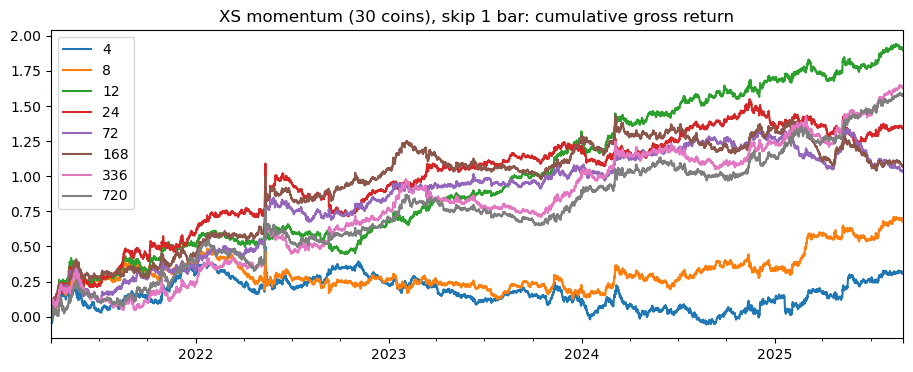

In [5]:
# stability: gross Sharpe by year (skip 1 bar)
g2 = gross_h.xs(2, axis=1, level=1)
display(g2.groupby(g2.index.year).apply(sharpe).round(2))
g2.cumsum().plot(figsize=(11, 4), title='XS momentum (30 coins), skip 1 bar: cumulative gross return');

**Conclusion (training period, Apr-2021 → Aug-2025, gross).**
- **The market is much harder than with 13 coins:** the equal-weight 30-coin market has a Sharpe of only 0.12 and 73% vol (BTC: 0.44). Many coins enter the universe near a volume peak and then fall.
- **Short-horizon reversal is weaker** than on Binance.US (h=4, no skip: −1.4 vs −3.4), consistent with cleaner global prices.
- **Skipping one bar, momentum is positive at every horizon.** h=12 is the highest (1.44) but will not survive costs; the slow horizons **h = 336 and 720 (1.20, 1.16)** are positive in **every year**, including 2025 (≈ 2), where 13-coin momentum was weak.
- Mid horizons (72h, 168h) are unstable (negative in Jan–Aug 2025).
- Next: costs, rebalance frequency and the cvxpy optimizer (Section 3).


## 3. Transaction costs and execution

Same steps as Section 3 of the 13-coin notebook, on the training period only. New column **`turnover from coin replacement`**: the share of turnover that comes from coins entering or leaving the universe (selling a coin that drops out, buying one that comes in).

### 3.1 Costs with 4-hourly rebalancing

In [6]:
gross_c, to_c, sw_c = {}, {}, {}
for h in hours:
    held = xs_momentum(ret, h, univ).shift(2)
    gross_c[h], to_c[h] = backtest(held, ret)
    sw_c[h] = replacement_turnover(held, 2, univ)
cost_table_u(pd.DataFrame(gross_c), pd.DataFrame(to_c), pd.DataFrame(sw_c)).round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps),turnover from coin replacement
4,0.246,-20.300,-6.971,1.339,0.238,0.001
8,0.519,-13.115,-4.315,0.939,0.747,0.002
12,1.440,-9.696,-2.510,0.772,2.541,0.002
24,0.993,-6.737,-1.748,0.550,2.527,0.003
72,0.764,-3.865,-0.867,0.326,3.273,0.005
168,0.781,-2.319,-0.308,0.221,5.018,0.008
336,1.196,-1.049,0.409,0.159,10.640,0.011
720,1.158,-0.391,0.615,0.109,14.945,0.016


### 3.2 Rebalance less often

The signal is still computed every 4h, but the position is only updated once a day (00:00 UTC) or once a week (Monday 00:00) and held in between. The universe changes on the 1st of the month at 00:00, which is also a daily rebalance time.

In [7]:
rebalance = {'every 4h': np.ones(len(ret), dtype=bool),
             'daily':    ret.index.hour == 0,
             'weekly':   (ret.index.dayofweek == 0) & (ret.index.hour == 0)}

gross_f, to_f, sw_f = {}, {}, {}
for freq, mask in rebalance.items():
    for h in hours:
        held = hold_at(xs_momentum(ret, h, univ), mask).shift(2)
        gross_f[(freq, h)], to_f[(freq, h)] = backtest(held, ret)
        sw_f[(freq, h)] = replacement_turnover(held, 2, univ)
freq_table = cost_table_u(pd.DataFrame(gross_f), pd.DataFrame(to_f), pd.DataFrame(sw_f))
for col, fmt in [('net Sharpe (20bps)', '{:.2f}'), ('breakeven (bps)', '{:.1f}'), ('turnover from coin replacement', '{:.1%}')]:
    display(freq_table[col].unstack(0)[list(rebalance)]
            .rename_axis(index='lookback h (hours)', columns='rebalance')
            .style.format(fmt).set_caption(f'XS momentum (30 coins): {col} by rebalance frequency'))

rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,-20.30,-1.75,0.03
8,-13.12,-2.14,-0.17
12,-9.70,-1.68,0.25
24,-6.74,-2.45,-0.27
72,-3.86,-1.11,-0.53
168,-2.32,-0.44,-0.35
336,-1.05,0.23,0.09
720,-0.39,0.47,0.15


rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,0.2,9.4,21.2
8,0.7,7.3,13.5
12,2.5,9.3,29.5
24,2.5,4.8,8.9
72,3.3,8.0,-2.0
168,5.0,12.9,5.5
336,10.6,25.4,25.5
720,14.9,35.5,32.2


rebalance,every 4h,daily,weekly
lookback h (hours),,,
4,0.1%,0.8%,0.7%
8,0.2%,0.8%,0.7%
12,0.2%,0.8%,0.8%
24,0.3%,0.8%,0.7%
72,0.5%,1.3%,0.7%
168,0.8%,2.0%,0.7%
336,1.1%,2.8%,0.9%
720,1.6%,4.0%,1.2%


In [8]:
# robustness: does the daily result depend on the hour of the day we rebalance? (net Sharpe, 20 bps)
rob_hour = {}
for hr in range(0, 24, 4):
    for h in [168, 336, 720]:
        g, t = backtest(hold_at(xs_momentum(ret, h, univ), ret.index.hour == hr).shift(2), ret)
        rob_hour[(hr, h)] = sharpe((g - COST*t).loc[EVAL_START:])
pd.Series(rob_hour).unstack().rename_axis(index='rebalance hour', columns='h').round(2)

h,168,336,720
rebalance hour,,,
0,-0.44,0.23,0.47
4,-0.42,0.17,0.46
8,-0.67,0.20,0.52
12,-0.78,0.18,0.48
16,-0.68,0.15,0.42
20,-0.89,-0.05,0.35


### 3.3 Optimization with a transaction-cost penalty (cvxpy)

Same problem as in the 13-coin notebook, every day at 00:00:

$$\min_w \;(w-w^*)^\top \Sigma\,(w-w^*) \;+\; \lambda \cdot c \cdot \lVert w - w_{prev}\rVert_1 \quad \text{s.t.}\quad \textstyle\sum_i w_i = 0,\;\; \lVert w\rVert_1 \le 1$$

Only change: it is solved **over the coins in today's universe**. A coin that left the universe is sold (weight 0); this cost does not depend on $w$, so it does not change the solution, but it is counted in turnover. Σ = Ledoit-Wolf covariance of the past 30 days of the coins in the universe.

λ = 0 must reproduce the daily rule of 3.2 (sanity check). Run for h = 336 and 720, the two slow horizons that survive costs.

In [9]:
gross_o, to_o, sw_o = {}, {}, {}
for h in [336, 720]:
    for pen in [0, 0.001, 0.003, 0.01]:
        held = rolling_opt(xs_momentum(ret, h, univ), ret, univ, tc_penalty=pen).reindex(ret.index).ffill().shift(2)
        gross_o[(h, pen)], to_o[(h, pen)] = backtest(held, ret)
        sw_o[(h, pen)] = replacement_turnover(held, 2, univ)
opt_table = cost_table_u(pd.DataFrame(gross_o), pd.DataFrame(to_o), pd.DataFrame(sw_o))
opt_table.index.names = ['h', 'tc_penalty']
opt_table.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  turnover from coin replacement
h   tc_penalty                                                                                                                    
336 0.000              1.108               0.235              0.803         0.061           25.400                           0.028
    0.001              1.026               0.397              0.806         0.044           32.631                           0.037
    0.003              0.960               0.491              0.796         0.032           40.998                           0.047
    0.010              0.916               0.633              0.817         0.017           64.750                           0.065
720 0.000              1.082               0.473              0.869         0.043           35.510                           0.040
    0.001              1.030               0.634              0.891         0.028           52.037                           0.059
    0.003              1.055               0.781              0.959         0.019           76.820                           0.079
    0.010              0.827               0.674              0.774         0.009          107.497                           0.121

In [10]:
# stability of the cost-aware momentum: net Sharpe (20 bps) by year
net_o = (pd.DataFrame(gross_o) - COST*pd.DataFrame(to_o)).loc[EVAL_START:]
net_o.groupby(net_o.index.year).apply(sharpe).round(2)

336                     720                  
     0.000 0.001 0.003 0.010 0.000 0.001 0.003 0.010
2021  0.16  0.31  0.47  0.87  0.94  1.06  1.28  1.52
2022  0.52  0.64  0.74  0.77  0.27  0.43  0.47  0.36
2023 -0.15  0.09  0.26  0.54 -0.22  0.07  0.35  0.05
2024 -0.15 -0.05 -0.06 -0.01  0.26  0.35  0.43  0.40
2025  0.91  1.15  1.24  1.20  1.42  1.60  1.80  1.21

**Conclusion (training period).** Same picture as with 13 coins, slightly better after costs:
- **Every 4h, costs kill everything**: the best break-even cost is 15 bps (h=720), below 20 bps.
- **Daily rebalancing** cuts turnover ~2.5× for slow signals: h=720 goes from −0.39 to **0.47** net (break-even 36 bps), h=336 to 0.25. Horizons ≤ 168h stay negative; weekly loses too much signal. The result does not depend on the rebalance hour (h=720: 0.35–0.52).
- **cvxpy** (h=720, λ = 0.003) halves turnover again (0.043 → 0.019) and raises the net Sharpe to **0.78** (break-even 77 bps), vs 0.69 with 13 coins. λ = 0 reproduces the daily rule (0.47, sanity check); λ = 0.01 trades too little. h=720 beats h=336 for every λ.
- **Coin replacement is a small part of the cost**: 4% of turnover with the daily rule, 8% with the optimizer (the optimizer cuts the other trades, but cannot avoid selling a coin that leaves the universe).
- By year the chosen setting (h=720, λ=0.003) is positive every year (0.35–1.80), weakest in 2023–2024.
- **Choice for the next steps: h = 720, daily, cvxpy λ = 0.003** — the same setting as in the 13-coin project, so nothing had to be re-tuned.


## 4. A better cross-sectional momentum signal

Same two changes as Section 4 of the 13-coin notebook, applied to the h = 720 signal:
1. **Multi-horizon**: average the ranks of h = 168, 336, 720 (1 week, 2 weeks, 1 month) instead of picking one horizon.
2. **Volatility-adjusted**: rank on past return ÷ past 30-day volatility, so a coin does not rank high just because it is volatile. This matters more with 30 coins: many newly listed coins are very volatile.

Ranks are taken **among the coins in the universe only**. Then the same daily rebalance + cvxpy (λ = 0.003).

In [11]:
# each change separately, then both (daily rebalance without optimizer, and with cvxpy)
signals = {'h=720':                        xs_momentum(ret, 720, univ),
           'h=720, vol-adjusted':          xs_momentum_mhva(ret, univ, horizons=(720,)),
           'multi-horizon':                norm(sum(xs_momentum(ret, h, univ).replace(0, np.nan).rank(axis=1) for h in (168, 336, 720)) / 3, univ),
           'multi-horizon + vol-adjusted': xs_momentum_mhva(ret, univ)}
daily = ret.index.hour == 0
gross_s, to_s, sw_s = {}, {}, {}
for name, w in signals.items():
    held = hold_at(w, daily).shift(2)
    gross_s[('daily', name)], to_s[('daily', name)] = backtest(held, ret)
    sw_s[('daily', name)] = replacement_turnover(held, 2, univ)
for name in ['h=720', 'multi-horizon + vol-adjusted']:
    W = rolling_opt(signals[name], ret, univ, tc_penalty=0.003)
    held = W.reindex(ret.index).ffill().shift(2)
    gross_s[('cvxpy 0.003', name)], to_s[('cvxpy 0.003', name)] = backtest(held, ret)
    sw_s[('cvxpy 0.003', name)] = replacement_turnover(held, 2, univ)
    if name != 'h=720':
        W_xs = W                                  # kept: this is the candidate final XS strategy
xs_table = cost_table_u(pd.DataFrame(gross_s), pd.DataFrame(to_s), pd.DataFrame(sw_s))
xs_table.index.names = ['execution', 'signal']
xs_table.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  turnover from coin replacement
execution   signal                                                                                                                                          
daily       h=720                                1.083               0.473              0.870         0.043           35.526                           0.040
            h=720, vol-adjusted                  1.446               0.721              1.193         0.045           39.934                           0.036
            multi-horizon                        1.196               0.343              0.897         0.064           28.059                           0.026
            multi-horizon + vol-adjusted         1.578               0.614              1.240         0.064           32.794                           0.024
cvxpy 0.003 h=720                                1.055               0.781              0.959         0.019           76.820                           0.079
            multi-horizon + vol-adjusted         1.462               1.019              1.307         0.029           66.107                           0.046

,h=720,multi-horizon + vol-adjusted
2021,1.28,1.75
2022,0.47,1.20
2023,0.35,0.33
2024,0.43,0.79
2025,1.80,0.89


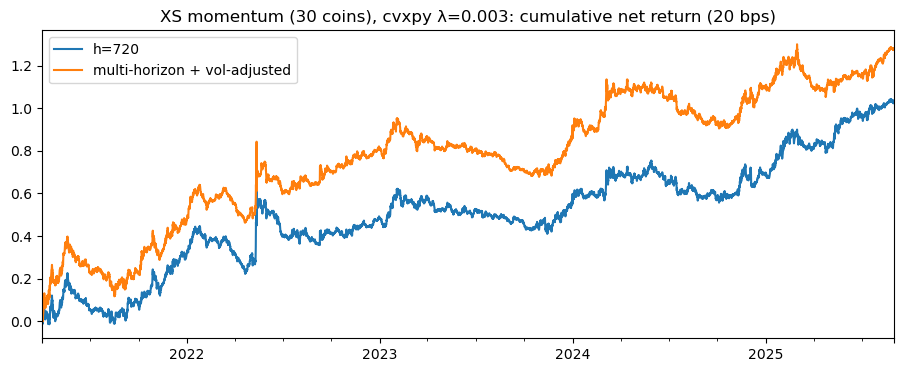

In [12]:
# stability: net Sharpe (20 bps) by year, cvxpy versions
net_s = (pd.DataFrame(gross_s) - COST*pd.DataFrame(to_s)).loc[EVAL_START:, 'cvxpy 0.003']
display(net_s.groupby(net_s.index.year).apply(sharpe).round(2))
net_s.cumsum().plot(figsize=(11, 4), title='XS momentum (30 coins), cvxpy λ=0.003: cumulative net return (20 bps)');

**Conclusion (training period).**
- **Volatility adjustment is the change that matters**: with daily rebalancing it raises the gross Sharpe of h=720 from 1.08 to 1.45 and the net from 0.47 to 0.72, at the same turnover. With 30 coins, many recently listed coins are very volatile, and plain ranks put them at the extremes.
- **Multi-horizon alone does not help after costs** (0.35 net): the 1-week rank changes often, so turnover rises by ~50%.
- **With the optimizer, multi-horizon + vol-adjusted gives net 1.02** (vs 0.78 for h=720), break-even 66 bps, and it is positive every year (0.33–1.75). As in the 13-coin project, the optimizer is what makes the faster signal tradable.
- Vol-adjusted h=720 alone is a reasonable alternative (it was better than the combined signal without the optimizer), but to avoid adding specifications we keep **the same signal as in the 13-coin project**.
- **Final XS strategy: multi-horizon + vol-adjusted, daily, cvxpy λ = 0.003** (`W_xs`). Next: time-series momentum (Section 6).


## 5. Momentum and activity (volume)

Same test as Section 5 of the 13-coin notebook. Project hypothesis: *heightened activity coupled with new information favors momentum.*

Abnormal volume of each coin, relative to its own past:

$$\text{avol}_{i,t} = \frac{\text{average 4h volume over the last } h \text{ hours}}{\text{average 4h volume over the last 90 days}}$$

Signals (h = 168 and 720): plain momentum; momentum **only among the high-avol half** of the coins in the universe; **only among the low-avol half**; and **volume-weighted** momentum (momentum rank × (1 + avol percentile)). Ranks and halves are taken among the coins in the universe. With 30 coins each half has ~15 coins (6–7 with 13 coins), so splitting costs less diversification.

In [13]:
vol4 = pd.read_pickle('data/global30_vol_1h.pk').loc[:TRAIN_END, ret.columns].resample('4h').sum(min_count=1)

vm = {}
for h in [168, 720]:
    avol = vol4.rolling(h//4, min_periods=h//4).mean() / vol4.rolling(540, min_periods=270).mean()
    mom = ret.rolling(h//4, min_periods=1).mean()
    valid = mom.notna() & avol.notna() & univ
    mom, avol = mom.where(valid), avol.where(valid)
    av_pct = avol.rank(axis=1, pct=True)
    high = av_pct > 0.5
    mom_rank = mom.rank(axis=1)
    vm[(h, 'plain')]           = norm(mom_rank, univ)
    vm[(h, 'high avol only')]  = norm(mom.where(high).rank(axis=1), univ)
    vm[(h, 'low avol only')]   = norm(mom.where(~high & valid).rank(axis=1), univ)
    vm[(h, 'volume-weighted')] = norm(mom_rank.sub(mom_rank.mean(axis=1), axis=0) * (1 + av_pct), univ)

vol_tab, net_vm = {}, {}
for (h, name), w in vm.items():
    g4, _ = backtest(w.shift(2), ret)                        # unconstrained, every 4h
    gd, td = backtest(hold_at(w, daily).shift(2), ret)       # daily rebalance, with costs
    net_vm[(h, name)] = (gd - COST*td).loc[EVAL_START:]
    vol_tab[(h, name)] = {'gross Sharpe (every 4h)': sharpe(g4.loc[EVAL_START:]),
                          'net Sharpe 20bps (daily)': sharpe(net_vm[(h, name)]),
                          'avg turnover (daily)': td.loc[EVAL_START:].mean()}
pd.DataFrame(vol_tab).T.round(3)

gross Sharpe (every 4h)  net Sharpe 20bps (daily)  avg turnover (daily)
168 plain                              0.781                    -0.437                 0.086
    high avol only                     0.883                    -0.282                 0.102
    low avol only                     -0.069                    -1.641                 0.113
    volume-weighted                    0.882                    -0.275                 0.086
720 plain                              1.158                     0.473                 0.043
    high avol only                     1.192                     0.572                 0.054
    low avol only                      0.937                     0.154                 0.064
    volume-weighted                    1.119                     0.437                 0.043

In [14]:
# by year: net Sharpe (20 bps, daily rebalance)
net_vm = pd.DataFrame(net_vm)
net_vm.groupby(net_vm.index.year).apply(sharpe).round(2)

168                                                720                                             
     plain high avol only low avol only volume-weighted plain high avol only low avol only volume-weighted
2021  0.41           1.19         -1.07            0.60  0.94           1.52          0.78            0.95
2022  0.61           0.24         -0.99            0.81  0.28           0.34          0.17            0.27
2023 -0.84          -0.85         -1.98           -0.75 -0.22          -0.13         -0.68           -0.19
2024 -0.46          -0.69         -1.26           -0.37  0.26           0.52         -0.05            0.22
2025 -2.68          -2.24         -3.44           -2.63  1.42           0.64          0.53            1.22

**Conclusion (training period).** **The hypothesis is clearer with 30 coins than with 13, but it is still not a tradable improvement.**
- Before costs, momentum among high-volume coins is stronger than among low-volume coins, and the gap is large: h=168: 0.88 vs −0.07; h=720: 1.19 vs 0.94 (13 coins: 1.10 vs 0.51 and 0.78 vs 0.57, before the change of Sharpe convention).
- After costs (daily), only h=720 is positive. **High-avol only: 0.57 vs 0.47 for plain momentum**, a small gain for ~25% more turnover, and not in every year (worse in 2025). Volume-weighting: 0.44, slightly below plain.
- Low-volume momentum is the weak part: negative every year for h=168, and the worst variant for h=720.
- A gain of 0.10 in Sharpe over 4.4 years is well within noise. As in the 13-coin project, **volume conditioning is not added to the final strategy** (it would also have to be combined with the vol-adjusted signal and the optimizer, i.e. more specifications tried on the same data).


## 6. Time-series momentum

TS momentum asks whether the **market** is trending: long if it rose over the last *L* days, short if it fell. Directional by design. Two choices for the trend indicator, and two for what is traded:

| | signal (trend of) | traded |
|---|---|---|
| **A** (13-coin method) | equal-weight market of the universe | equal-weight market of the universe |
| **B** | BTC | equal-weight market of the universe |
| **C** | BTC | BTC only |

Why BTC: it is the most liquid coin and leads the market; the equal-weight market of 30 coins is noisier (73% vol) and contains many recently listed coins.

Lookbacks L = 7, 14, 30, 60 days, and the **average of the four signs** (position between −1 and +1). Daily rebalance, `shift(2)`.

In [15]:
xs_net = (lambda g, t: g - COST*t)(*backtest(W_xs.reindex(ret.index).ffill().shift(2), ret))   # final XS strategy
ew = equal_weight(univ)
variants = {'A: market → market': (ts_signal(mkt), lambda s: ew.mul(s, axis=0)),
            'B: BTC → market':    (ts_signal(btc), lambda s: ew.mul(s, axis=0)),
            'C: BTC → BTC':       (ts_signal(btc), lambda s: only('BTCUSDT', s, ret))}

gross_t, to_t = {}, {}
for v, (sigs, position) in variants.items():
    for name, s in sigs.items():
        gross_t[(v, name)], to_t[(v, name)] = backtest(hold_at(position(s), daily).shift(2), ret)
gross_t, to_t = pd.DataFrame(gross_t), pd.DataFrame(to_t)
net_t = (gross_t - COST*to_t).loc[EVAL_START:]

ts_table = cost_table(gross_t, to_t)
ts_table['annual vol'] = to_daily(net_t).std()*np.sqrt(DAYS_PER_YEAR)
ts_table['max drawdown'] = net_t.apply(max_drawdown)
ts_table['corr with XS'] = net_t.corrwith(xs_net.loc[EVAL_START:])
ts_table['beta to market'] = net_t.apply(lambda x: perf(x, mkt)['beta'])
ts_table.index.names = ['variant', 'lookback']
ts_table.round(3)

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  annual vol  max drawdown  corr with XS  beta to market
variant            lookback                                                                                                                                                 
A: market → market 7d                    0.514               0.273              0.429         0.058           42.824       0.729        -1.249         0.111          -0.234
                   14d                   0.139              -0.028              0.080         0.040           16.674       0.729        -1.240         0.122          -0.185
                   30d                   0.310               0.197              0.270         0.027           54.891       0.734        -1.062         0.104          -0.157
                   60d                   0.324               0.244              0.296         0.019           80.980       0.727        -1.077         0.104           0.086
                   average 7-60d         0.434               0.251              0.370         0.033           47.629       0.540        -0.630         0.146          -0.123
B: BTC → market    7d                    0.092              -0.174             -0.001         0.064            6.899       0.731        -2.220         0.041          -0.199
                   14d                   0.194               0.010              0.130         0.045           21.093       0.737        -1.492         0.062          -0.125
                   30d                   0.375               0.248              0.331         0.031           59.100       0.738        -1.467         0.046          -0.170
                   60d                   0.403               0.326              0.376         0.019          104.866       0.742        -1.593         0.040          -0.050
                   average 7-60d         0.339               0.149              0.273         0.036           35.764       0.579        -1.116         0.060          -0.136
C: BTC → BTC       7d                   -0.141              -0.539             -0.281         0.063           -7.048       0.478        -2.048         0.021          -0.094
                   14d                   0.265              -0.010              0.169         0.044           19.246       0.479        -0.854         0.036          -0.064
                   30d                   0.542               0.354              0.476         0.030           58.188       0.481        -0.747         0.039          -0.097
                   60d                   0.315               0.205              0.276         0.017           57.484       0.480        -0.924         0.020          -0.027
                   average 7-60d         0.322               0.028              0.219         0.035           21.922       0.366        -0.639         0.037          -0.071

,A: market → market,B: BTC → market,C: BTC → BTC
2021,0.27,0.34,-0.30
2022,0.48,-0.09,-0.35
2023,0.73,1.14,1.07
2024,0.05,-0.49,0.14
2025,-0.46,0.03,-0.26


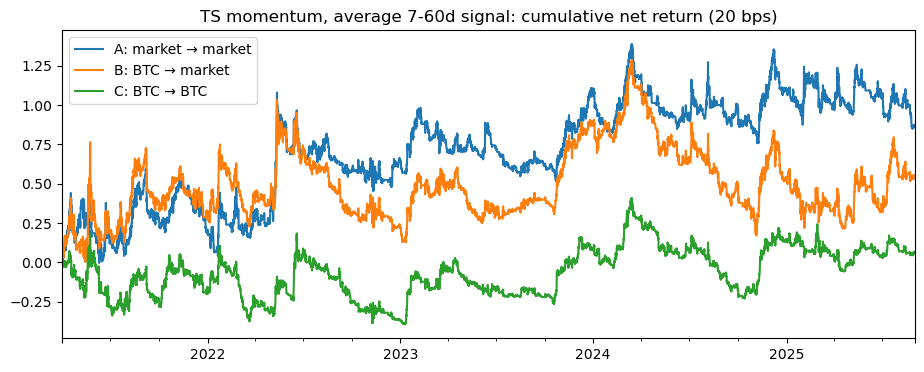

In [16]:
# stability of the averaged signals: net Sharpe (20 bps) by year
avg = net_t.xs('average 7-60d', axis=1, level=1)
display(avg.groupby(avg.index.year).apply(sharpe).round(2))
avg.cumsum().plot(figsize=(11, 4), title='TS momentum, average 7-60d signal: cumulative net return (20 bps)');

### 6.1 Market signal with the current universe (A2)

In A, the market return is the return of the equal-weight portfolio **that was held** at each bar, so after the monthly change of coins, the L-day signal is still mostly based on the coins that just left. Alternative **A2**: at time *t*, take the coins **currently** in the universe and average their own past L-day returns:

$$\text{signal}_t = \text{sign}\Big(\frac{1}{N_t}\sum_{i \in U_t} \bar r_{i,t}(L)\Big)$$

with $\bar r_{i,t}(L)$ the average 4h return of coin *i* over the last L days (average rather than sum, so a coin with a few missing bars is not dropped; the sign is the same when the window is complete). This is closer to the idea of TS momentum: *is the basket I am about to hold trending?* Possible bias: coins enter the universe after a volume spike, which often comes with a price rise.

**Decision rule, fixed before looking at the result:** A2 replaces A only if its net Sharpe (average 7–60d) is at least **0.1 higher** than A's; otherwise A is kept.

In [17]:
sig_a, sig_a2 = ts_signal(mkt), ts_signal_current(ret, univ)
g2, t2 = {}, {}
for name, s in sig_a2.items():
    g2[('A2: current coins → market', name)], t2[('A2: current coins → market', name)] = backtest(hold_at(ew.mul(s, axis=0), daily).shift(2), ret)
g2, t2 = pd.DataFrame(g2), pd.DataFrame(t2)
net_a2 = (g2 - COST*t2).loc[EVAL_START:]

a2_table = cost_table(g2, t2)
a2_table['annual vol'] = to_daily(net_a2).std()*np.sqrt(DAYS_PER_YEAR)
a2_table['max drawdown'] = net_a2.apply(max_drawdown)
a2_table['corr with XS'] = net_a2.corrwith(xs_net.loc[EVAL_START:])
a2_table['beta to market'] = net_a2.apply(lambda x: perf(x, mkt)['beta'])
a2_table.index.names = ['variant', 'lookback']
display(pd.concat([ts_table.loc[['A: market → market']], a2_table]).round(3))

# how often do A and A2 disagree? (daily signal at 00:00, training period)
d = daily & (ret.index >= EVAL_START)
diff = pd.DataFrame({L: (sig_a[L][d] != sig_a2[L][d]) for L in ['7d', '14d', '30d', '60d']})
first_week = diff.index.day <= 7
pd.DataFrame({'days with a different sign': diff.mean(),
              '... in the first 7 days of a month': diff[first_week].mean(),
              '... rest of the month': diff[~first_week].mean()}).T.style.format('{:.1%}')

gross Sharpe  net Sharpe (20bps)  net Sharpe (7bps)  avg turnover  breakeven (bps)  annual vol  max drawdown  corr with XS  beta to market
variant                    lookback                                                                                                                                                 
A: market → market         7d                    0.514               0.273              0.429         0.058           42.824       0.729        -1.249         0.111          -0.234
                           14d                   0.139              -0.028              0.080         0.040           16.674       0.729        -1.240         0.122          -0.185
                           30d                   0.310               0.197              0.270         0.027           54.891       0.734        -1.062         0.104          -0.157
                           60d                   0.324               0.244              0.296         0.019           80.980       0.727        -1.077         0.104           0.086
                           average 7-60d         0.434               0.251              0.370         0.033           47.629       0.540        -0.630         0.146          -0.123
A2: current coins → market 7d                    0.566               0.323              0.481         0.058           46.716       0.727        -1.250         0.112          -0.233
                           14d                   0.296               0.132              0.239         0.039           36.095       0.724        -0.937         0.125          -0.195
                           30d                   0.293               0.185              0.256         0.026           54.328       0.734        -1.430         0.099          -0.110
                           60d                   0.071              -0.012              0.042         0.020           17.141       0.729        -1.303         0.111           0.158
                           average 7-60d         0.418               0.233              0.353         0.032           45.362       0.534        -0.573         0.149          -0.095

,7d,14d,30d,60d
days with a different sign,0.7%,1.1%,2.8%,7.6%
... in the first 7 days of a month,3.2%,2.7%,4.6%,12.1%
... rest of the month,0.0%,0.6%,2.3%,6.2%


In [18]:
# by year: net Sharpe (20 bps) of the averaged signals
both = pd.DataFrame({'A': net_t[('A: market → market', 'average 7-60d')],
                     'A2': net_a2[('A2: current coins → market', 'average 7-60d')]})
both.groupby(both.index.year).apply(sharpe).round(2)

,A,A2
2021,0.27,0.27
2022,0.48,0.32
2023,0.73,0.78
2024,0.05,0.24
2025,-0.46,-0.60


In [19]:
# decision rule (fixed before looking at the result): A2 replaces A only if its net Sharpe is at least 0.1 higher
gain_a2 = sharpe(net_a2[('A2: current coins → market', 'average 7-60d')]) - sharpe(net_t[('A: market → market', 'average 7-60d')])
TS_VARIANT = 'A2' if gain_a2 >= 0.1 else 'A'
TS_SIGNAL = (sig_a2 if TS_VARIANT == 'A2' else sig_a)['average 7-60d']
print(f'A2 minus A: {gain_a2:+.3f} Sharpe -> TS uses {TS_VARIANT}')

A2 minus A: -0.018 Sharpe -> TS uses A


**Conclusion (training period).** TS momentum is **much weaker than with 13 coins** (net 0.76 there):
- **A (13-coin method) is the best of the averaged signals: net 0.25**, vol 54%, max drawdown −63%. B (BTC signal, trade the market) 0.15; C (BTC only) 0.03.
- **Using BTC as the indicator does not help.** BTC's own trend is no better a guide for the 30-coin market than the market's own trend, and trading BTC alone is the weakest.
- Single lookbacks are unstable (from −0.54 to 0.35, best lookback differs by variant): picking one would be overfitting.
- Not stable over time: A is positive in 2021–2024 but −0.46 in Jan–Aug 2025.
- Still a diversifier: low correlation with XS (0.15) and a negative beta (−0.12), because it is short in falling markets.
- **A2 (current coins' own past returns) changes almost nothing**: net 0.23 vs 0.25 for A. The two signals agree on 93–99% of days (60d: 7% different, mostly in the first week of a month, right after the coin change; 7d: under 1%). By the decision rule (A2 needs +0.1), **A is kept**.
- **Candidate TS strategy: A, average 7–60d** (same as the 13-coin project). Whether it is worth including is decided in the combination step (Section 9), on the training period.


## 7. Reversal

Same ideas as Section 7 of the 13-coin notebook. There, short-term reversal and pairs trading looked profitable on Binance.US but mostly disappeared on Binance global (stale prices of thin coins create fake reversal). The 30-coin universe is on Binance global, so this is the clean-data version, with more and smaller coins.

### 7.1 Short-term cross-sectional reversal

Minus the 4h momentum weights (ranked among the coins in the universe), no skip (`shift(1)`), rebalanced every 4h.

In [20]:
g, t = backtest((-xs_momentum(ret, 4, univ)).shift(1), ret)
rev_table = cost_table(pd.DataFrame({'4h reversal': g}), pd.DataFrame({'4h reversal': t}))
display(rev_table.round(3))
net_rev = (g - COST*t).loc[EVAL_START:]
pd.DataFrame({'gross': g.loc[EVAL_START:], 'net (20bps)': net_rev}).groupby(net_rev.index.year).apply(sharpe).round(2)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
4h reversal,1.381,-18.894,-5.496,1.339,1.425


,gross,net (20bps)
2021,1.30,-13.91
2022,2.87,-16.42
2023,0.96,-26.02
2024,0.81,-22.75
2025,0.53,-19.98


### 7.2 Pairs trading

Same rules as the 13-coin notebook: spread = log(A) − β·log(B) with β from a 30-day rolling regression; z = (spread − 30-day mean) / 30-day std. Open when |z| > 2.5 (short the spread if high, long if low), close when |z| < 0.5. Each pair has gross exposure 1.

With a changing universe:
- a pair can only be open when **both coins are in the universe**; if one of them leaves, the pair is closed;
- the portfolio is the **average over the pairs that are eligible** at that time (both coins in the universe: C(30, 2) = 435 pairs), the same scaling as the average over the 78 pairs with 13 coins;
- 5,220 pairs are eligible at some point in the training period (~5 minutes to run).

In [21]:
px4 = pd.read_pickle('data/global30_px_1h.pk').loc[:TRAIN_END, ret.columns].resample('4h').last()

g_p, t_p = pairs_trading(ret, px4, univ)
pair_table = cost_table(pd.DataFrame({'pairs': g_p}), pd.DataFrame({'pairs': t_p}))
display(pair_table.round(3))
net_p = (g_p - COST*t_p).loc[EVAL_START:]
pd.DataFrame({'gross': g_p.loc[EVAL_START:], 'net (20bps)': net_p}).groupby(net_p.index.year).apply(sharpe).round(2)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps)
pairs,0.005,-0.757,-0.262,0.009,0.129


,gross,net (20bps)
2021,-0.28,-0.82
2022,-0.33,-0.94
2023,0.18,-1.12
2024,0.68,-0.17
2025,-0.02,-1.06


**Conclusion (training period).** Both confirm the 13-coin result on clean data:
- **Short-term reversal exists but is not tradable.** Gross Sharpe 1.38 (13 coins: 2.8 on Binance.US, 1.3 on Binance global), positive every year and strongest in 2022, but the break-even cost is **1.4 bps** vs 20 bps of real cost: net −19.
- **Pairs trading does not work on clean data**: gross 0.01, net −0.76 (break-even 0.1 bps), negative after costs in every year. With 13 coins it was 0.63 on Binance.US and ~0 on Binance global; 30 coins and 435 pairs at a time do not change this. Its profits on Binance.US came from stale prices, not from real mean reversion between coins.
- Neither is used in the final strategy. Next: fire sale (7.3).


### 7.3 Fire sale

Same rule as the 13-coin notebook: sharp market-wide drops are often driven by **forced liquidations** and panic (uninformed selling). If the equal-weight market's 24h return is below **−k** standard deviations (90-day vol), **buy all coins in the universe** (equal weight) and hold for 24 hours; otherwise stay flat. Main setting k = 2, no skip (`shift(1)`).

The 30-coin market contains more small coins than the 13-coin one; they usually fall more in a crash and may rebound more.

In [22]:
fs_tab = {}
for k in [1.5, 2.0, 2.5]:
    w, s = fire_sale(mkt, ew, k)
    g, t = backtest(w.shift(1), ret)
    row = cost_table(pd.DataFrame({'x': g}), pd.DataFrame({'x': t})).iloc[0]
    s = s.loc[EVAL_START:]
    row['time in market'] = (s > 0).mean()
    row['events'] = (s.diff() > 0).sum()
    fs_tab[k] = row
fs_table = pd.DataFrame(fs_tab).T
fs_table.index.name = 'k'
fs_table.round(3)

,gross Sharpe,net Sharpe (20bps),net Sharpe (7bps),avg turnover,breakeven (bps),time in market,events
k,,,,,,,
1.5,0.687,0.440,0.601,0.034,55.186,0.151,164.0
2.0,0.609,0.437,0.549,0.018,70.777,0.076,88.0
2.5,0.648,0.557,0.616,0.009,139.404,0.038,44.0


In [23]:
# real reversal or just "crypto went up"? market return in the 24h after a crash vs on average
w_fs, s_fs = fire_sale(mkt, ew, 2.0)
in_mkt = (s_fs.shift(1) > 0).loc[EVAL_START:]
m_tr = mkt.loc[EVAL_START:]
print(f'average 4h market return, all bars:        {m_tr.mean()*1e4:5.1f} bps')
print(f'average 4h market return, 24h after crash: {m_tr[in_mkt].mean()*1e4:5.1f} bps')

# robustness: threshold x holding period x delay (net Sharpe, 20 bps)
rob = {}
for k in [1.5, 2.0, 2.5]:
    for hold in [3, 6, 12]:
        for lag in [1, 2]:
            g, t = backtest(fire_sale(mkt, ew, k, hold)[0].shift(lag), ret)
            rob[(k, hold*4, lag)] = sharpe((g - COST*t).loc[EVAL_START:])
rob = pd.Series(rob)
rob.index.names = ['k', 'hold (hours)', 'lag']
display(rob.unstack(['hold (hours)', 'lag']).round(2))

g, t = backtest(w_fs.shift(1), ret)
net_fs = (g - COST*t).loc[EVAL_START:]
net_fs.groupby(net_fs.index.year).apply(sharpe).round(2).rename('net Sharpe by year (k=2)')

average 4h market return, all bars:          0.6 bps
average 4h market return, 24h after crash:  16.9 bps


hold (hours)    12          24          48      
lag              1     2     1     2     1     2
k                                               
1.5           0.36  0.37  0.44  0.20  0.27  0.21
2.0           0.62  0.52  0.44  0.15  0.20  0.07
2.5           0.71  0.62  0.56  0.37  0.16  0.14

2021    0.93
2022   -0.24
2023    1.05
2024    1.14
2025   -0.62
Name: net Sharpe by year (k=2), dtype: float64

**Conclusion (training period).** **Fire sale still works, but it is weaker than with 13 coins.**
- k = 2: **net Sharpe 0.44** (13 coins on Binance global: 0.70), break-even 71 bps, in the market 8% of the time, 88 events.
- **It is real reversal, not "crypto went up"**: in the 24h after a crash the market earns 16.9 bps per 4h vs 0.6 bps on average. With 30 coins the average market return is close to zero, so the whole profit comes from the rebound.
- **Robust**: positive for every threshold, holding period and delay (lag 1: 0.16–0.71; weaker with a 2-bar delay). Shorter holding (12h) and stricter thresholds are a bit better, but **k = 2, 24h is kept** (the 13-coin setting) to avoid choosing the best cell of the grid.
- Uneven over time: strong in 2021, 2023, 2024 (0.9–1.1), negative in 2022 (−0.24; crashes that kept going: LUNA, FTX) and in Jan–Aug 2025 (−0.62).
- **Candidate FS strategy: k = 2, hold 24h, lag 1.** Next: betting against beta (Section 8).


## 8. Betting against beta (BAB)

Same rule as Section 8 of the 13-coin notebook (Frazzini & Pedersen, 2014): investors who cannot or will not use leverage buy high-beta assets, which makes them expensive and lowers their future returns.

Each month (1st, 00:00, the same time as the universe change): estimate each coin's beta to the equal-weight market of the universe (past 90 days); **among the coins in the universe**, long the low-beta half and short the high-beta half, each leg scaled by 1/(its average beta) so the two legs have similar market exposure. Monthly rebalance, so costs are small.

In [24]:
monthly = (ret.index.day == 1) & (ret.index.hour == 0)
w_bab, beta_coins = betting_against_beta(ret, mkt, univ)
held_bab = hold_at(w_bab, monthly).shift(1)
g, t = backtest(held_bab, ret)
net_bab = (g - COST*t).loc[EVAL_START:]
m_tr = mkt.loc[EVAL_START:]
b = to_daily(net_bab).cov(to_daily(m_tr)) / to_daily(m_tr).var()
display(pd.Series({'net Sharpe (20bps)': sharpe(net_bab), 'breakeven (bps)': g.loc[EVAL_START:].mean()/t.loc[EVAL_START:].mean()*1e4,
                   'avg net exposure': held_bab.sum(axis=1).loc[EVAL_START:].mean(), 'beta': b,
                   'Sharpe of (net - beta x market)': sharpe(net_bab - b*m_tr),
                   'corr with XS': net_bab.corr(xs_net.loc[EVAL_START:])}).round(3).to_frame('BAB, 30 coins'))

# average beta of the two legs, and by-year net Sharpe
legs = pd.DataFrame({'low-beta leg': beta_coins.where(w_bab > 0).mean(axis=1), 'high-beta leg': beta_coins.where(w_bab < 0).mean(axis=1)})
display(legs[monthly].loc[EVAL_START:].mean().round(2).to_frame('average beta at rebalance').T)
net_bab.groupby(net_bab.index.year).apply(sharpe).round(2).rename('BAB net Sharpe by year')

,"BAB, 30 coins"
net Sharpe (20bps),0.634
breakeven (bps),236.475
avg net exposure,0.195
beta,0.041
Sharpe of (net - beta x market),0.624
corr with XS,0.150


,low-beta leg,high-beta leg
average beta at rebalance,0.81,1.2


2021    0.41
2022    1.18
2023   -0.26
2024    0.84
2025    0.94
Name: BAB net Sharpe by year, dtype: float64

### 8.1 Beta to BTC instead of the equal-weight market

The final strategy is evaluated by its alpha and beta **versus BTC** (daily regression). Using the beta to BTC to build BAB makes it BTC-neutral by construction, and BTC (over half of crypto market cap) is closer to the value-weighted market of the original paper. Note that the regression alpha already removes any BTC exposure, so this is a design choice, not a correction.

Same rule otherwise: rank the coins in the universe on their 90-day beta **to BTC**, long the low half, short the high half, each leg scaled by 1/(its average beta).

**Decision rule, fixed before looking at the result:** the BTC version replaces the market version only if its net Sharpe is at least **0.1 higher**.

In [25]:
w_bab_btc, beta_btc = betting_against_beta_to(ret, btc, univ)
g_b, t_b = backtest(hold_at(w_bab_btc, monthly).shift(1), ret)
net_bab_btc = (g_b - COST*t_b).loc[EVAL_START:]

cmp = {}
for name, x, bc, w in [('beta to market', net_bab, beta_coins, w_bab), ('beta to BTC', net_bab_btc, beta_btc, w_bab_btc)]:
    ab = alpha_beta(x, btc)
    cmp[name] = {'net Sharpe (20bps)': sharpe(x), 'beta to market': perf(x, mkt)['beta'],
                 'beta to BTC': ab['beta'], 'annual alpha vs BTC': ab['annual alpha'], 't-stat alpha vs BTC': ab['t-stat (alpha)'],
                 'avg beta, low leg': bc.where(w > 0)[monthly].loc[EVAL_START:].mean(axis=1).mean(),
                 'avg beta, high leg': bc.where(w < 0)[monthly].loc[EVAL_START:].mean(axis=1).mean(),
                 'corr with XS': x.corr(xs_net.loc[EVAL_START:])}
display(pd.DataFrame(cmp).round(3))

# how different are the two portfolios? share of coins in the same leg at each rebalance
same = (np.sign(w_bab[monthly]) == np.sign(w_bab_btc[monthly])) & univ[monthly]
print(f'coins in the same leg in both versions: {(same.sum(axis=1)/univ[monthly].sum(axis=1)).loc[EVAL_START:].mean():.0%}')
both = pd.DataFrame({'beta to market': net_bab, 'beta to BTC': net_bab_btc})
both.groupby(both.index.year).apply(sharpe).round(2)

,beta to market,beta to BTC
net Sharpe (20bps),0.634,0.284
beta to market,0.041,0.030
beta to BTC,0.089,0.067
annual alpha vs BTC,0.072,0.024
t-stat alpha vs BTC,1.337,0.469
"avg beta, low leg",0.810,1.075
"avg beta, high leg",1.204,1.529
corr with XS,0.150,0.126


coins in the same leg in both versions: 89%


,beta to market,beta to BTC
2021,0.41,0.10
2022,1.18,0.76
2023,-0.26,-0.83
2024,0.84,0.35
2025,0.94,1.09


In [26]:
# decision rule (fixed before looking at the result): betas to BTC replace betas to the market only if the net Sharpe is at least 0.1 higher
gain_btc = sharpe(net_bab_btc) - sharpe(net_bab)
BAB_BETA = 'BTC' if gain_btc >= 0.1 else 'market'
W_BAB = w_bab_btc if BAB_BETA == 'BTC' else w_bab
print(f'BTC beta minus market beta: {gain_btc:+.3f} Sharpe -> BAB uses betas to the {BAB_BETA}')

BTC beta minus market beta: -0.350 Sharpe -> BAB uses betas to the market


**Conclusion (training period).** **BAB works better with 30 coins than with 13.**
- **Net Sharpe 0.63** (13 coins: 0.66 on 2020–2025, but only 0.22 over Mar-2021 → 2025), with almost no market exposure: beta 0.05, and **0.62 after removing the market**, so it is not a hidden long position.
- The legs are well separated (average beta 0.81 vs 1.20 at rebalance); the low-beta leg is levered up, hence a net long exposure of ~0.2 in dollars but ~0 in beta.
- Costs are small (break-even 236 bps), although higher than with 13 coins (~600 bps) because coins enter and leave the universe every month.
- Positive in 4 of 5 years (best 2022: 1.18, when high-beta coins crashed); negative in 2023 (−0.26), a rebound year where high-beta coins led.
- Correlation with XS 0.15 (13 coins: −0.11): still low, a good diversifier.
- **Beta to BTC instead of the market (8.1) is worse: net 0.28 vs 0.63**, negative in 2023 (−0.83), alpha vs BTC t-stat 0.5 vs 1.3. The two portfolios hold 89% of coins on the same side, so the difference comes from the coins near the median and the leg scaling. Both versions already have a small beta to BTC (0.09 and 0.07), so the BTC version buys little extra neutrality. By the decision rule, **the market version is kept**.
- **Candidate BAB strategy: betas to the equal-weight market** (as in the 13-coin project). Next: combining the four strategies (Section 9).


## 9. Combining the strategies

The four candidate strategies, each net of 20 bps, exactly as chosen above:

| | strategy | rebalance |
|---|---|---|
| **XS** | multi-horizon + vol-adjusted momentum, cvxpy (λ = 0.003) | daily |
| **TS** | market time-series momentum, average 7–60d (A or A2, by the rule in 6.1) | daily |
| **FS** | fire sale, k = 2, hold 24h | event-driven |
| **BAB** | betting against beta (market or BTC betas, by the rule in 8.1) | monthly |

Combination methods (capital share of each strategy), as in Section 9 of the 13-coin notebook:
- **equal** (1/N)
- **risk parity**: share ∝ 1/vol over the past year (lagged one bar)
- **rolling max Sharpe**: $w \propto \Sigma^{-1}\mu$ on all past data (≥ 1 year), negative weights set to 0, updated weekly
- **full-sample max Sharpe** \*: same formula on the evaluation period itself. It **uses future data** (of the training period) and is only an upper bound.

Strategy sets: all four; without TS (its training Sharpe is low); without BAB (the 3-strategy set of the 13-coin project).

**Decision rule for TS, fixed before looking at the result:** TS stays (as in the 13-coin project) unless removing it raises the risk-parity Sharpe by at least **0.1**.

In [27]:
ts_sig = TS_SIGNAL                                     # A or A2, by the rule in 6.1
held = {'XS':  W_xs.reindex(ret.index).ffill().shift(2),
        'TS':  hold_at(ew.mul(ts_sig, axis=0), daily).shift(2),
        'FS':  fire_sale(mkt, ew, 2.0)[0].shift(1),
        'BAB': hold_at(W_BAB, monthly).shift(1)}                 # market or BTC betas, by the rule in 8.1
R = pd.DataFrame({k: (lambda g, t: g - COST*t)(*backtest(h, ret)) for k, h in held.items()})
R = R.loc[ts_sig.first_valid_index() + pd.Timedelta('1D'):]      # from the first full TS signal (warm-up)
print('strategies from', R.index[0].date(), '| evaluation from', EVAL_START)
R.loc[EVAL_START:].corr().round(2)

strategies from 2020-03-01 | evaluation from 2021-04-01


,XS,TS,FS,BAB
XS,1.00,0.15,-0.07,0.15
TS,0.15,1.00,-0.24,0.04
FS,-0.07,-0.24,1.00,0.09
BAB,0.15,0.04,0.09,1.00


In [28]:
combos = combinations(R, EVAL_START, SETS)
pd.DataFrame({c: perf(combos[c], mkt) for c in combos}).T.round(3)

,Sharpe,annual return,annual vol,max drawdown,beta
XS,1.019,0.199,0.196,-0.281,-0.030
TS,0.251,0.136,0.540,-0.630,-0.123
FS,0.437,0.140,0.320,-0.548,0.187
BAB,0.634,0.091,0.143,-0.271,0.041
4 strategies: equal,0.879,0.142,0.161,-0.192,0.019
4 strategies: risk parity,1.152,0.140,0.121,-0.145,0.027
4 strategies: rolling max Sharpe,0.985,0.129,0.131,-0.185,0.013
4 strategies: full-sample max Sharpe *,1.250,0.149,0.119,-0.142,0.026
3 (no TS): equal,1.066,0.143,0.135,-0.165,0.066
3 (no TS): risk parity,1.202,0.143,0.119,-0.154,0.046


In [29]:
# risk-parity capital shares over time (4 strategies)
rp_w = risk_parity(R, SETS['4 strategies']).loc[EVAL_START:]
display(rp_w.groupby(rp_w.index.year).mean().round(2).rename_axis('average risk-parity share'))

# by year: net Sharpe of each strategy and of the risk-parity combinations
cols_y = ['XS', 'TS', 'FS', 'BAB', '4 strategies: risk parity', '3 (no TS): risk parity', '3 (no BAB): risk parity']
combos[cols_y].groupby(combos.index.year).apply(sharpe).round(2)

,XS,TS,FS,BAB
average risk-parity share,,,,
2021,0.31,0.11,0.17,0.40
2022,0.27,0.11,0.18,0.44
2023,0.28,0.10,0.20,0.41
2024,0.28,0.11,0.22,0.39
2025,0.31,0.11,0.17,0.42


,XS,TS,FS,BAB,4 strategies: risk parity,3 (no TS): risk parity,3 (no BAB): risk parity
2021,1.75,0.27,0.93,0.41,1.60,1.63,1.85
2022,1.20,0.48,-0.24,1.18,1.23,1.11,0.77
2023,0.33,0.73,1.05,-0.26,0.72,0.53,0.92
2024,0.79,0.05,1.14,0.84,1.40,1.58,1.23
2025,0.89,-0.46,-0.62,0.94,0.53,0.95,0.07


## 10. Performance evaluation (training period)

Alpha and beta from a regression of **daily** returns on the equal-weight market of the universe and on BTC.

risk parity without TS minus with TS: +0.051 Sharpe -> keep TS


,4 strategies: risk parity
Sharpe,1.152
annual return,0.140
annual vol,0.121
max drawdown,-0.145
beta,0.027


,vs equal-weight market,vs BTC
beta,0.027,0.053
annual alpha,0.138,0.129
t-stat (alpha),2.907,2.746


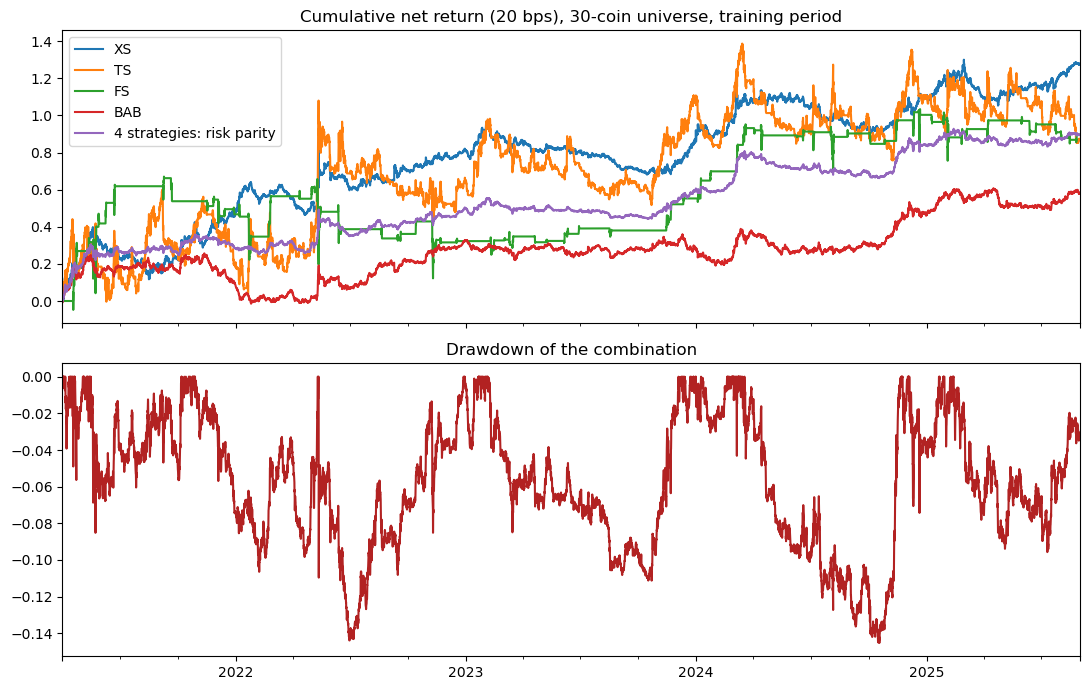

In [30]:
final_name = '4 strategies: risk parity'          # updated below if the decision rule drops TS
gain = sharpe(combos['3 (no TS): risk parity']) - sharpe(combos['4 strategies: risk parity'])
print(f'risk parity without TS minus with TS: {gain:+.3f} Sharpe ->', 'drop TS' if gain >= 0.1 else 'keep TS')
if gain >= 0.1:
    final_name = '3 (no TS): risk parity'
final = combos[final_name]

display(perf(final, mkt).round(3).to_frame(final_name))
display(pd.DataFrame({'vs equal-weight market': alpha_beta(final, mkt), 'vs BTC': alpha_beta(final, btc)}).round(3))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
combos[['XS', 'TS', 'FS', 'BAB', final_name]].cumsum().plot(ax=ax[0], title='Cumulative net return (20 bps), 30-coin universe, training period')
cum = final.cumsum()
(cum - cum.cummax()).plot(ax=ax[1], color='firebrick', title='Drawdown of the combination')
plt.tight_layout()

**Conclusion (training period, Apr-2021 → Aug-2025).**
- The four strategies are almost uncorrelated (largest: TS–FS −0.24, after a crash TS is often short while FS is long; XS–TS 0.15, XS–BAB 0.15).
- **Risk parity is the best realistic method**: 4 strategies → **Sharpe 1.15**, annual return 14% (252-day convention), vol 12%, max drawdown −15%. It is close to the full-sample max Sharpe (1.25), which uses future data. Rolling max Sharpe (0.99) and equal weights (0.88) are worse, as with 13 coins.
- **TS is kept**: removing it gives 1.20 (+0.05), below the +0.1 threshold fixed in advance. Risk parity already gives TS only ~11% of the capital because of its high vol, so it matters little either way.
- **BAB matters more than with 13 coins**: without it the risk-parity Sharpe falls to 1.03, and it gets the largest share (~42%) because of its low vol.
- **Market-neutral**: beta 0.03 to the equal-weight market and 0.05 to BTC. **Alpha vs BTC ≈ 12.9% per year, t-stat 2.7** (daily regression).
- Positive every year (0.53–1.60); weakest in Jan–Aug 2025, when TS and FS lost.
- Comparable to the 13-coin result on Binance.US (1.24, t-stat 3.1), but now on a point-in-time universe of 30 coins with delisted coins included and parameters chosen only on the training period.
- **Final strategy: 4 strategies, risk parity.** Everything is now fixed; the next step is the single run on the test period (Section 11).


## 11. Test period (Sep-2025 → Oct-2026)

Same code and settings as chosen in Sections 2–10, now on the full data. Every signal only uses past data, so the training-period results must be unchanged (checked below).

**Runs.** The first test run (1-Nov-2026) gave **0.62** (2026: −0.35). A bug was then found in the universe (stablecoins UST, USD1 and the gold token XAUT had entered it, against the rule of Step 1); after the fix, the training was re-run with every decision rule executed in code and **every choice stayed the same**. The results below are the second run. Sep-2025 → Oct-2026 was already partly seen in the 13-coin version of the project, so the first truly unseen data start in Nov-2026.

In [31]:
# switch to the full data (training + test)
ret = ret_all.loc[:, univ_all.any()]
univ = univ_all[ret.columns]
ew = equal_weight(univ)
mkt = (ew.shift(1)*ret).sum(axis=1)
btc = ret['BTCUSDT']
daily = ret.index.hour == 0
monthly = (ret.index.day == 1) & daily

W_xs_all = rolling_opt(xs_momentum_mhva(ret, univ), ret, univ, tc_penalty=0.003)          # ~1 minute
ts_all = (ts_signal(mkt) if TS_VARIANT == 'A' else ts_signal_current(ret, univ))['average 7-60d']
w_bab_all, beta_all = betting_against_beta(ret, mkt, univ) if BAB_BETA == 'market' else betting_against_beta_to(ret, btc, univ)
held_all = {'XS':  W_xs_all.reindex(ret.index).ffill().shift(2),
            'TS':  hold_at(ew.mul(ts_all, axis=0), daily).shift(2),
            'FS':  fire_sale(mkt, ew, 2.0)[0].shift(1),
            'BAB': hold_at(w_bab_all, monthly).shift(1)}
R_all = pd.DataFrame({k: (lambda g, t: g - COST*t)(*backtest(h, ret)) for k, h in held_all.items()})
R_all = R_all.loc[ts_all.first_valid_index() + pd.Timedelta('1D'):]
final_cols = SETS['4 strategies'] if final_name.startswith('4') else SETS['3 (no TS)']
R_all['final'] = (risk_parity(R_all, final_cols)*R_all[final_cols]).sum(axis=1)

# check: the training period is reproduced exactly
assert np.allclose(R_all.loc[EVAL_START:TRAIN_END, ['XS', 'TS', 'FS', 'BAB']], R.loc[EVAL_START:TRAIN_END, ['XS', 'TS', 'FS', 'BAB']])
assert np.allclose(R_all.loc[EVAL_START:TRAIN_END, 'final'], combos[final_name].loc[:TRAIN_END])
print('check passed: training-period results reproduced on the full data')

check passed: training-period results reproduced on the full data


In [32]:
# check: price gaps of selected coins in the test period (the stop rule must not trigger on short gaps)
sel = univ.groupby(univ.index.to_period('M')).transform('any')     # coins selected for the month
miss = (sel & ret.isna()).loc[TEST_START:]
gaps = []
for c in miss.columns[miss.any()]:
    s = miss[c]
    g = (s != s.shift()).cumsum()[s]
    for _, grp in s[s].groupby(g):
        gaps.append({'coin': c, 'start': grp.index[0], 'bars': len(grp), 'stops for good': ret[c].loc[grp.index[0]:].notna().sum() == 0})
gaps = pd.DataFrame(gaps)
display(gaps if len(gaps) else 'no gaps')
wide = ret.loc[TEST_START:].notna().where(sel.loc[TEST_START:]).mean(axis=1) < 0.5
print('bars where most selected coins have no price:', int(wide.sum()))

,coin,start,bars,stops for good
0,TONUSDT,2026-06-30 04:00:00,5,True


bars where most selected coins have no price: 0


In [33]:
periods = {'training (Apr-2021 → Aug-2025)': (EVAL_START, TRAIN_END),
           'TEST (Sep-2025 → Oct-2026)':      (TEST_START, None),
           '  Sep–Dec 2025':                  ('2025-09', '2025-12'),
           '  2026 Jan–Oct':                  ('2026-01', '2026-10')}
res = {}
for p, (a, b) in periods.items():
    x = R_all.loc[a:b, 'final']
    ab = alpha_beta(x, btc)
    res[p] = pd.concat([perf(x, mkt), ab.rename({'beta': 'beta to BTC', 'annual alpha': 'alpha vs BTC', 't-stat (alpha)': 't-stat alpha vs BTC'})])
display(pd.DataFrame(res).T.round(3).style.format('{:.3f}').set_caption('Final strategy (4 strategies, risk parity), net of 20 bps'))
display(pd.DataFrame({p: sharpe(R_all.loc[a:b]) for p, (a, b) in periods.items()}).T.round(2).rename_axis('net Sharpe'))
n = to_daily(R_all.loc[TEST_START:, 'final']).shape[0]
print(f'test period: {n} days, standard error of the Sharpe ratio ≈ {np.sqrt(DAYS_PER_YEAR/n):.2f}')

,Sharpe,annual return,annual vol,max drawdown,beta,beta to BTC,alpha vs BTC,t-stat alpha vs BTC
training (Apr-2021 → Aug-2025),1.152,0.140,0.121,-0.145,0.027,0.053,0.129,2.746
TEST (Sep-2025 → Oct-2026),0.320,0.025,0.077,-0.118,0.005,0.037,0.030,0.509
Sep–Dec 2025,2.581,0.217,0.084,-0.029,-0.065,-0.078,0.188,1.626
2026 Jan–Oct,-0.722,-0.053,0.073,-0.113,0.053,0.071,-0.050,-0.800


,XS,TS,FS,BAB,final
net Sharpe,,,,,
training (Apr-2021 → Aug-2025),1.02,0.25,0.44,0.63,1.15
TEST (Sep-2025 → Oct-2026),1.18,0.20,1.06,-1.88,0.32
Sep–Dec 2025,1.40,0.76,1.90,0.98,2.58
2026 Jan–Oct,1.09,-0.11,0.73,-2.82,-0.72


test period: 426 days, standard error of the Sharpe ratio ≈ 0.77


,market (30 coins),BTC,XS,TS,FS,BAB,final
month (return %),,,,,,,
2025-09,-1.1,5.5,1.2,1.0,-1.0,1.6,0.9
2025-10,-18.8,-3.2,3.6,8.0,20.0,1.8,6.3
2025-11,-21.6,-18.3,5.1,12.4,-5.7,0.0,1.8
2025-12,-10.0,-2.2,0.8,-3.3,6.8,1.0,1.5
2026-01,-13.5,-10.1,-3.6,9.0,-1.8,-3.1,-1.8
2026-02,-12.8,-14.7,-2.4,4.0,-2.5,-0.7,-1.1
2026-03,-0.4,2.8,2.8,-9.4,1.0,-0.2,0.1
2026-04,10.6,11.8,15.3,3.0,0.0,-10.3,0.6
2026-05,5.4,-3.2,16.7,-6.5,6.1,-2.8,4.1


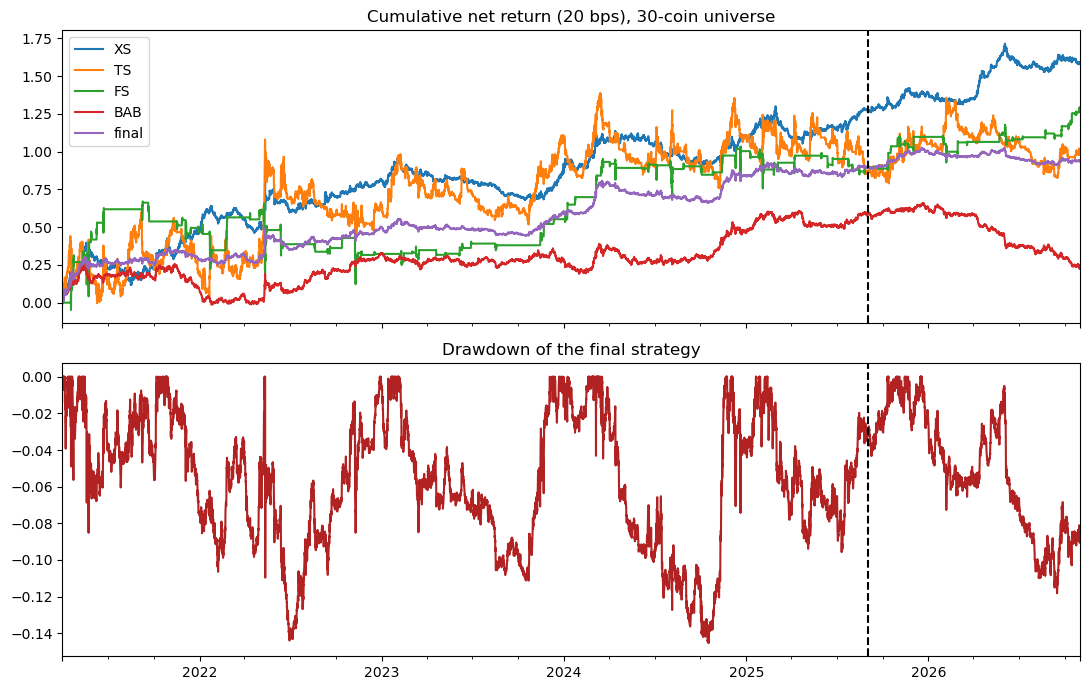

In [34]:
# market context and monthly returns in the test period (%)
test = R_all.loc[TEST_START:]
mon = pd.concat({'market (30 coins)': mkt.loc[TEST_START:], 'BTC': btc.loc[TEST_START:], **{c: test[c] for c in ['XS', 'TS', 'FS', 'BAB', 'final']}}, axis=1)
display((mon.groupby(mon.index.to_period('M')).sum()*100).round(1).rename_axis('month (return %)'))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
R_all.loc[EVAL_START:].cumsum().plot(ax=ax[0], title='Cumulative net return (20 bps), 30-coin universe')
ax[0].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
cum = R_all.loc[EVAL_START:, 'final'].cumsum()
(cum - cum.cummax()).plot(ax=ax[1], color='firebrick', title='Drawdown of the final strategy')
ax[1].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
plt.tight_layout()

### 11.1 Why did BAB fail in 2026?

Equal-weight returns of the low-beta and high-beta halves (as selected by BAB each month), their betas, and their beta-adjusted returns (alpha vs the equal-weight market, daily regression).

In [35]:
lo = beta_all.rank(axis=1, pct=True) <= 0.5
hi = ~lo & beta_all.notna()
lo_m = lo[monthly].reindex(ret.index).ffill().shift(1).fillna(False)
hi_m = hi[monthly].reindex(ret.index).ffill().shift(1).fillna(False)
legs = pd.DataFrame({'low-beta half': ret.where(lo_m).mean(axis=1), 'high-beta half': ret.where(hi_m).mean(axis=1)}).fillna(0)

diag = {}
for p, (a, b) in {'training': (EVAL_START, TRAIN_END), 'Sep–Dec 2025': ('2025-09', '2025-12'), '2026 Jan–Oct': ('2026-01', '2026-10')}.items():
    row = {}
    for leg in legs:
        ab = alpha_beta(legs[leg].loc[a:b], mkt)
        row[(leg, 'beta')] = ab['beta']
        row[(leg, 'alpha % / yr')] = ab['annual alpha']*100
    row[('ex-ante beta', 'low')] = beta_all.where(lo)[monthly].loc[a:b].mean(axis=1).mean()
    row[('ex-ante beta', 'high')] = beta_all.where(hi)[monthly].loc[a:b].mean(axis=1).mean()
    diag[p] = row
display(pd.DataFrame(diag).T.round(2))
m26 = pd.concat({'market': mkt, **{c: legs[c] for c in legs}, 'BAB': R_all['BAB']}, axis=1).loc['2026']
(m26.groupby(m26.index.month).sum()*100).round(1).rename_axis('2026 month (return %)')

low-beta half              high-beta half              ex-ante beta      
                      beta alpha % / yr           beta alpha % / yr          low  high
training              0.86         8.53           1.14        -8.60         0.81  1.20
Sep–Dec 2025          0.81        12.43           1.19       -12.43         0.76  1.21
2026 Jan–Oct          0.80       -35.22           1.20        35.12         0.72  1.23

,market,low-beta half,high-beta half,BAB
2026 month (return %),,,,
1,-13.5,-13.8,-13.3,-3.1
2,-12.8,-10.6,-15.0,-0.7
3,-0.4,-0.4,-0.4,-0.2
4,10.6,-1.8,23.0,-10.3
5,5.4,1.2,9.6,-2.8
6,-19.6,-22.4,-16.8,-8.3
7,3.0,0.8,5.2,-1.6
8,18.6,14.1,23.0,1.2
9,24.1,7.2,41.0,-7.8


**Conclusion (test period, Sep-2025 → Oct-2026).**
- **Checks passed**: the training results are reproduced exactly on the full data; the only price gap in the test period is TON, which stops trading for good on 30-Jun-2026.
- **Final strategy: net Sharpe 0.32** (annual return 2.5% with the 252-day convention, vol 8%, max drawdown −12%, beta to BTC 0.04, alpha vs BTC t-stat 0.5). **Sep–Dec 2025: 2.58; 2026 Jan–Oct: −0.72.** With 426 days the standard error of the Sharpe ratio is ≈ 0.8, so the gap to training (1.15) is about one standard error. Over the period the market fell (sum of monthly returns: 30-coin market −53%, BTC −24%) and the strategy stayed close to flat.
- **Momentum did not fail with 30 coins**: XS has a Sharpe of 1.18 over the test period and **1.09 in 2026**, vs −0.87 in 2026 with 13 coins. The 2026 momentum weakness of the 13-coin project was a small-universe problem.
- Fire sale worked (1.06; 2026: 0.73); TS was about flat (0.20).
- **BAB broke down in 2026 (−2.82)** and explains the weak year: it had the largest risk-parity share (~41%).
- **Why BAB failed (11.1):** the betas were estimated well (ex-ante 0.72 / 1.23, realized 0.80 / 1.20), but the **low-beta premium reversed**: the low-beta half earned +8.5% a year of alpha in training and −35% in 2026, the high-beta half the opposite. In rebounds the speculative high-beta coins rose much more (Apr-2026: +23% vs −2%; Sep-2026: +41% vs +7%), while in sell-offs the low-beta coins fell as much (Jun-2026: −22% vs −17%). BAB assumes low-beta coins move less in both directions; in 2026 they had the downside without the upside.


## 12. Handling the failure of BAB: rolling max-Sharpe weights and a 30% cap

Risk parity looks only at volatility, so it kept ~41% of the capital in BAB while BAB lost money steadily in 2026. Two responses, compared with the baseline:

| method | rule |
|---|---|
| **baseline** | risk parity (1-year vol), the final strategy |
| **cap 30%** | risk-parity shares capped at 30% per strategy; the excess stays in cash |
| **rolling max Sharpe** | $w \propto \Sigma^{-1}\mu$ on all past data (≥ 1 year), negative weights set to 0, updated weekly (Section 9): the weights look at past *returns*, so a strategy that keeps losing is cut |
| *equal weight* | 1/4 each, for reference |

Shares are updated once a day; **every method pays 20 bps on the change of each share** (so the baseline is slightly below the numbers above).

**How to read it:** the training period shows the cost of each method in normal times. The 2026 failure of BAB was already known when these methods were looked at, so **the test results are post-hoc**: they show what the method would have done, not proof that it works.

In [36]:
daily_t = R_all.index[R_all.index.hour == 0]
cols4 = ['XS', 'TS', 'FS', 'BAB']
Rs = R_all[cols4]
base = risk_parity(Rs, cols4)
shares = {'baseline (risk parity)': base,
          'cap 30%':                base.clip(upper=0.30),
          'rolling max Sharpe':     rolling_max_sharpe(Rs, cols4),
          'equal weight':           pd.DataFrame(0.25, index=Rs.index, columns=cols4)}

port, Wsh = {}, {}
for name, w in shares.items():
    port[name], Wsh[name] = run_shares(w, Rs, daily_t)
port = pd.DataFrame(port)

tr = pd.DataFrame({n: summary(port[n], EVAL_START, TRAIN_END) for n in port}).T
tr['avg invested share'] = [Wsh[n].loc[EVAL_START:TRAIN_END].sum(axis=1).mean() for n in port]
display(tr.round(3).style.format('{:.3f}').set_caption('Training period (Apr-2021 → Aug-2025): cost in normal times'))
display(pd.DataFrame({p: sharpe(port.loc[a:b]) for p, (a, b) in periods.items()}).round(2).style.format('{:.2f}')
        .set_caption('Net Sharpe by period (test columns are post-hoc)'))

,Sharpe,annual return,max drawdown,worst year Sharpe,avg invested share
baseline (risk parity),1.155,0.140,-0.145,0.535,1.000
cap 30%,1.156,0.130,-0.141,0.446,0.882
rolling max Sharpe,0.986,0.130,-0.190,0.559,1.000
equal weight,0.879,0.142,-0.192,-0.087,1.000


,training (Apr-2021 → Aug-2025),TEST (Sep-2025 → Oct-2026),Sep–Dec 2025,2026 Jan–Oct
baseline (risk parity),1.16,0.31,2.57,-0.73
cap 30%,1.16,0.62,2.55,-0.30
rolling max Sharpe,0.99,0.90,2.37,0.28
equal weight,0.88,0.67,2.10,-0.12


,baseline (risk parity),cap 30%,rolling max Sharpe,equal weight
average BAB share,,,,
2025-09,0.41,0.3,0.33,0.25
2025-10,0.42,0.3,0.33,0.25
2025-11,0.42,0.3,0.32,0.25
2025-12,0.43,0.3,0.32,0.25
2026-01,0.42,0.3,0.32,0.25
2026-02,0.40,0.3,0.31,0.25
2026-03,0.40,0.3,0.31,0.25
2026-04,0.40,0.3,0.28,0.25
2026-05,0.40,0.3,0.25,0.25


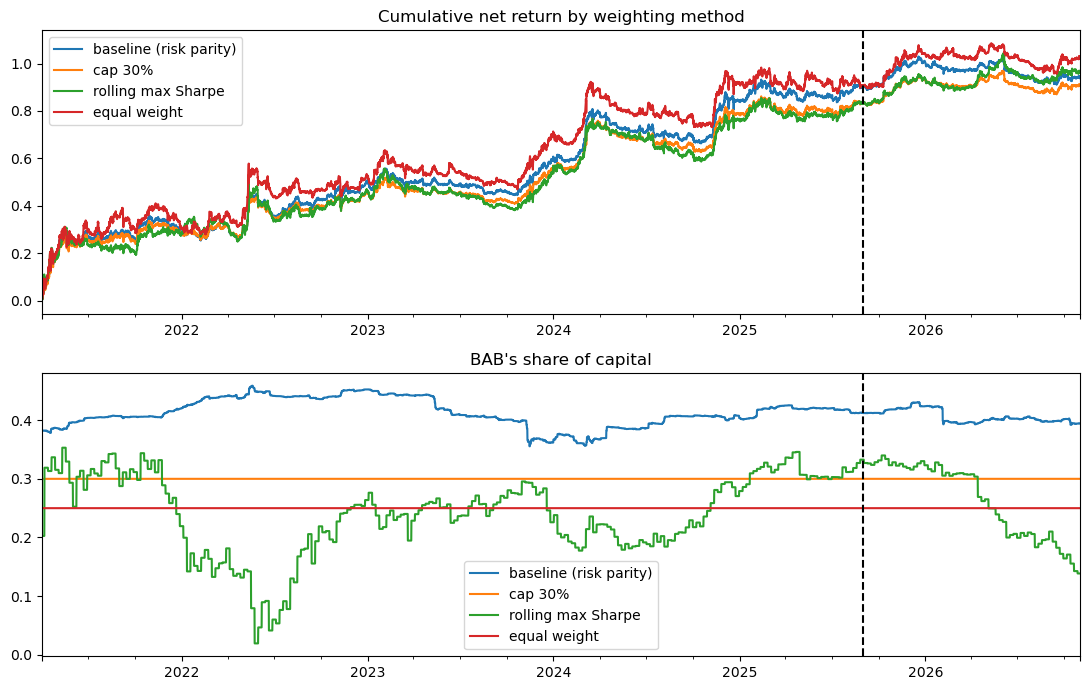

In [37]:
# BAB's share of capital by month in the test period
bab = pd.DataFrame({n: Wsh[n]['BAB'] for n in Wsh}).loc[TEST_START:]
display(bab.groupby(bab.index.to_period('M')).mean().round(2).rename_axis("average BAB share"))

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
port.loc[EVAL_START:].cumsum().plot(ax=ax[0], title='Cumulative net return by weighting method')
ax[0].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
pd.DataFrame({n: Wsh[n]['BAB'] for n in Wsh}).loc[EVAL_START:].plot(ax=ax[1], title="BAB's share of capital")
ax[1].axvline(pd.Timestamp(TEST_START), color='k', ls='--')
plt.tight_layout()

**Conclusion.**
- **Training period (cost in normal times):** the **30% cap is free** (Sharpe 1.156 vs 1.155, slightly lower drawdown, 12% of the capital in cash on average); **rolling max Sharpe costs 0.17** (0.99), because past mean returns are noisy estimates; equal weight is worse (0.88).
- **Test period (post-hoc):** baseline 0.31 (2026: −0.73); **cap 30%: 0.62 (2026: −0.30)**; **rolling max Sharpe: 0.90 (2026: +0.28)**; equal weight 0.67.
- **How they act on BAB:** the cap limits BAB to 30% from the start but cannot react to its losses; rolling max Sharpe starts lower (~33%, because BAB's past mean return was modest) and cuts BAB as its returns fall, to 15% by Oct-2026. Risk parity keeps ~40% throughout.
- **Trade-off:** methods that look at past returns (rolling max Sharpe, or a drawdown stop) protect against a strategy that stops working, but cost Sharpe in normal times, when a few bad months are noise. A cap prevents concentration without having to detect failure, so it has no cost in normal times but helps less.
- **Choice:** judged on training only, the **30% cap** is the rule to adopt (no cost, halves the damage of the BAB failure). Rolling max Sharpe would have done better in 2026, but choosing it now, after seeing 2026, would be hindsight. Both are to be evaluated on new data from Nov-2026.


## 13. Conclusions and limitations

**What worked (training Apr-2021 → Aug-2025, net of 20 bps)**
1. **Cross-sectional momentum** (multi-horizon + volatility-adjusted, daily, cvxpy cost-aware optimizer): net Sharpe 1.02, and it kept working in the test period (1.18; 2026: 1.09).
2. **Fire sale** (buy the market after a liquidation-driven crash): 0.44 in training, 1.06 in the test.
3. **Betting against beta**: 0.63 in training, but it broke down in 2026 (−2.8), when the low-beta premium reversed.
4. **Time-series momentum** on the market: weak (0.25), kept as a diversifier by a rule fixed in advance.
5. **Risk-parity combination**: Sharpe 1.15, beta to BTC 0.05, alpha vs BTC 12.9% a year (t-stat 2.7). **Test: 0.32** (Sep–Dec 2025: 2.58; 2026: −0.72).

**What did not work**
- Short-horizon reversal (break-even ~1.4 bps) and pairs trading (net −0.76): their profits on Binance.US were mostly stale prices of thin coins.
- Volume conditioning: consistent with the hypothesis (momentum is stronger among high-activity coins), but the gain after costs is too small.
- BTC as the trend indicator for TS, betas to BTC for BAB, and the current-universe TS signal (A2): all rejected by rules fixed before looking.

**What the larger universe changed**
- With a point-in-time 30-coin universe, momentum did not fail in 2026: the weakness seen with 13 coins was a small-universe problem.
- The new risk revealed by the test is **concentration**: risk parity gave ~41% to the lowest-volatility strategy (BAB), which then failed. A 30% cap per strategy costs nothing in training and halves the damage (Section 12).

**Method**
- Every choice was made on the training period, mostly by rules fixed before looking at the result (and executed in code). The test was run once, then a second time after fixing a universe bug (stablecoins), with the worse result reported.

**Limitations**
- Short test period (426 days, standard error of the Sharpe ≈ 0.8), and it was partly seen in the 13-coin version; **the first truly unseen data start in Nov-2026**.
- Many specifications tried on the same training data → training Sharpes are optimistic.
- Costs are a single estimate (20 bps); no funding cost for the short legs (perpetual futures) and no borrow constraints; weight drift between rebalances is ignored.
- Delisted coins are closed at their last price; in a halt the real exit price can be worse.
- Tokenized stocks listed on Binance in 2026 (e.g. SPCXB, SNDKB) are kept in the universe.
- Annual returns use the 252-day course convention; over 365 calendar days they are ~1.45× larger.
